# BÁO CÁO LAB 02: KIỂM ĐỊNH ADF VÀ MÔ HÌNH ARIMA/SARIMA - DATASET 01
## I. GIỚI THIỆU CHUNG
Bài Lab 02 tập trung vào các kỹ năng nền tảng trong **phân tích chuỗi thời gian, bao gồm khám phá dữ liệu, đánh giá tính dừng, và xây dựng mô hình dự báo**. Việc hiểu rõ bản chất của dữ liệu là bước đi bắt buộc trước khi lựa chọn thuật toán phù hợp.

Các nội dung chính của bài Lab:

**Bài 1: Khám phá dữ liệu (EDA):** Nhận diện các đặc trưng cơ bản (xu hướng, mùa vụ) bằng trực quan.

**Bài 2: Kiểm định ADF:** Định lượng tính dừng của chuỗi dữ liệu gốc.

**Bài 3: Sai phân & Kiểm định lại:** Kỹ thuật xử lý chuỗi không dừng.

**Bài 4: Phân tích ACF & PACF:** Cơ sở lý thuyết để chọn tham số cho mô hình.

**Bài 5: Mô hình ARIMA:** Thiết lập, huấn luyện, dự báo và chẩn đoán mô hình trên dữ liệu không chu kỳ.


**Về Dataset: Monthly Retail Sales**

Bộ dữ liệu Monthly Retail Sales ghi nhận doanh số bán lẻ hàng tháng, với các đặc điểm cơ bản sau:

Số lượng quan sát: 204 dòng (tương ứng với 204 tháng).

Giai đoạn: Bắt đầu từ tháng 07/1991 và kết thúc vào tháng 06/2008 (trải dài đúng 17 năm).

Cột dữ liệu:

date: Thời gian.

value: Doanh số bán lẻ (giá trị trung bình là 10.69, thấp nhất là 2.81 và cao nhất đạt 29.66).

## II. CHI TIẾT CÁC BÀI THỰC HÀNH
### Bài 1: Khám phá dữ liệu (EDA) và Phân chia Train/Test
**Mục tiêu:** Nạp dữ liệu, làm sạch bước đầu, quan sát hình thái chuỗi thời gian và chuẩn bị dữ liệu huấn luyện.

**Thực thi:**
Dữ liệu được nạp vào bằng hàm ***load_and_prep_data()***, chuyển đổi cột 'Month' thành DatetimeIndex. Tập dữ liệu sau đó được chia theo tỷ lệ **80% (Train) và 20% (Test)**. Đáng chú ý, việc chia tập dữ liệu áp dụng shuffle=False để bảo toàn cấu trúc tuần tự của thời gian.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.model_selection import train_test_split
from pathlib import Path

# Định vị thư mục gốc để import module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    if project_root.parent == project_root:
        break # Tránh lặp vô hạn nếu không tìm thấy src
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import các hàm bạn đã viết sẵn từ module
from src.lab02_utils.stats import perform_adf_test, significant_lags, plot_acf_pacf
from src.lab02_utils.modeling import (
    fit_arima, fit_sarima, residual_diagnostics, 
    forecast_test, evaluate_forecast, calculate_metrics, 
    plot_forecast, plot_arima_vs_sarima, plot_log_transformation
)

# Cấu hình hiển thị biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Khởi tạo thư mục xuất ảnh cho Dataset 1
fig_dir = project_root / 'reports' / 'figures' / 'lab02_dataset1'
fig_dir.mkdir(parents=True, exist_ok=True)
processed_dir = project_root / 'data' / 'processed' / 'lab02_dataset1'
processed_dir.mkdir(parents=True, exist_ok=True)

In [2]:
data_path = project_root / 'data' / 'raw' / 'Monthly Retail Sales.csv'
date_col_name = 'date'
value_col_name = 'value'

print(f"Đang đọc dữ liệu từ: {data_path}")
try:
    df = pd.read_csv(data_path, parse_dates=[date_col_name], index_col=date_col_name)
    print("\n1. Thông tin dữ liệu:")
    df.info()
    print("\n2. Dữ liệu đầu vào:")
    display(df.head())
    print("\n3. Thống kê mô tả:")
    display(df["value"].describe().to_frame())

    print("\n4. Kiểm tra dữ liệu thiếu:")
    print(df.isna().sum())

    print("\n5. Kiểm tra số quan sát:")
    print("Số dòng:", len(df))
    print("Số giá trị thiếu:", df["value"].isna().sum())

except Exception as e:
    print(f"Lỗi đọc file: {e}")
    

Đang đọc dữ liệu từ: d:\vscode\Lab_TimeSeries\data\raw\Monthly Retail Sales.csv

1. Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 204 entries, 1991-07-01 to 2008-06-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   204 non-null    float64
dtypes: float64(1)
memory usage: 3.2 KB

2. Dữ liệu đầu vào:


,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869



3. Thống kê mô tả:


,value
count,204.000000
mean,10.694430
std,5.956998
min,2.814520
25%,5.844095
50%,9.319345
75%,14.289964
max,29.665356



4. Kiểm tra dữ liệu thiếu:
value    0
dtype: int64

5. Kiểm tra số quan sát:
Số dòng: 204
Số giá trị thiếu: 0


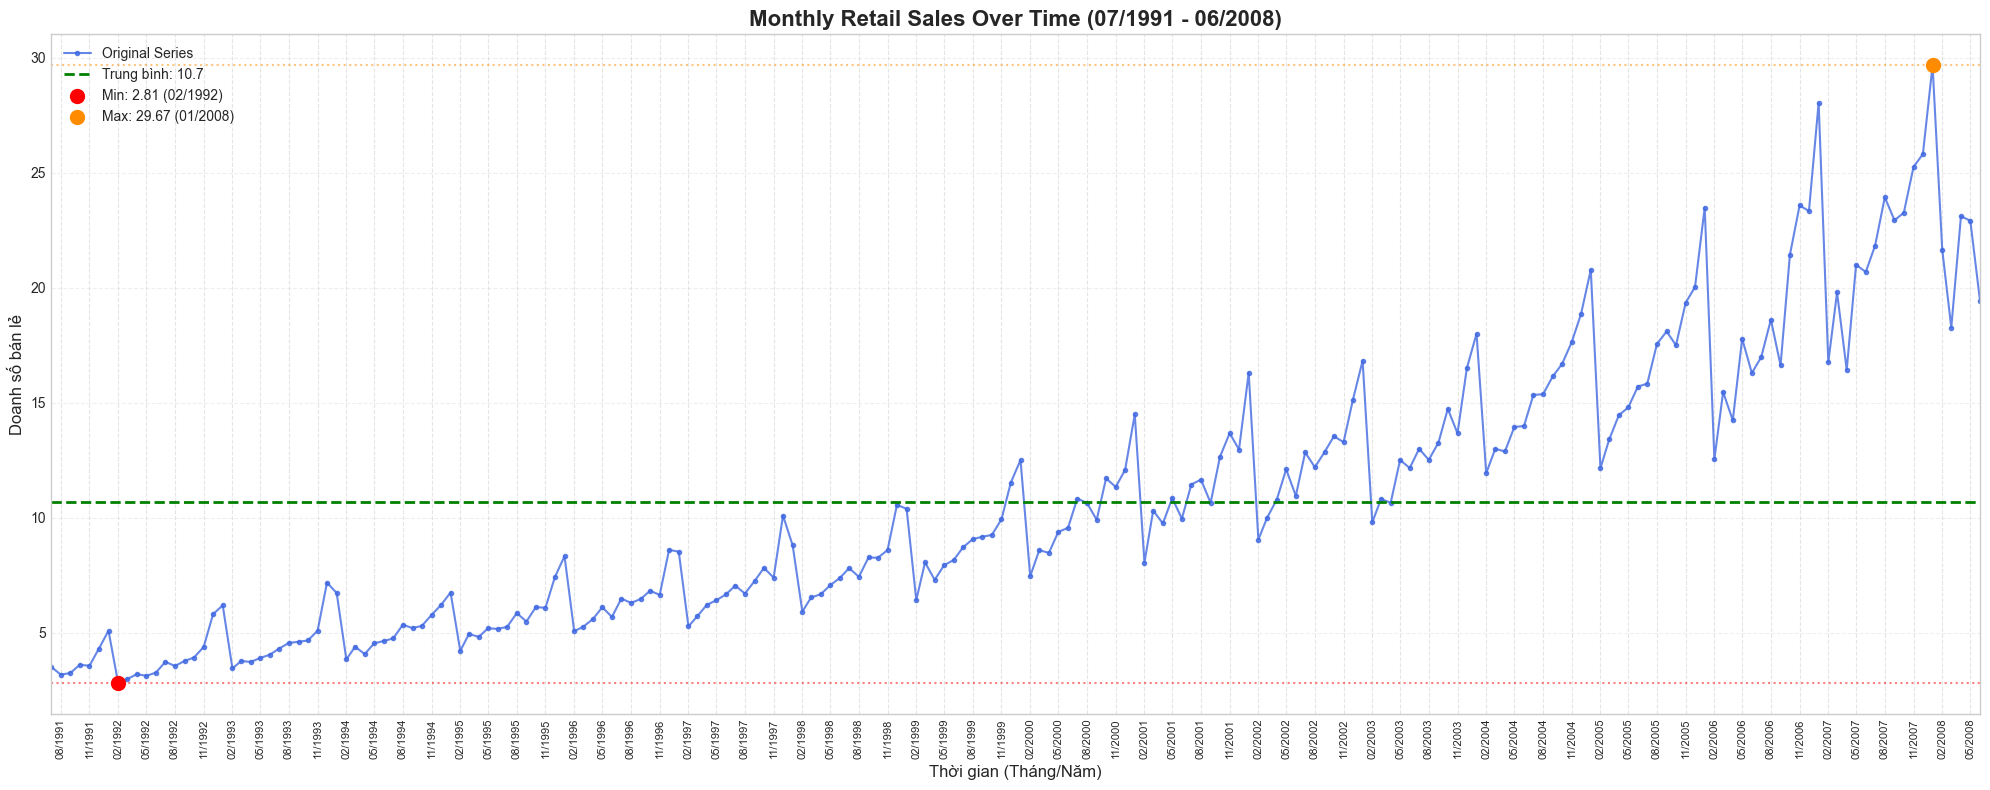

In [3]:
df = pd.read_csv(data_path, parse_dates=['date'], index_col='date')
min_val = df['value'].min()
max_val = df['value'].max()
mean_val = df['value'].mean()
min_date = df['value'].idxmin()
max_date = df['value'].idxmax()

plt.figure(figsize=(20, 8)) 

plt.plot(df.index, df['value'], color='royalblue', label='Original Series', marker='.', alpha=0.8)

plt.axhline(mean_val, color='green', linestyle='--', linewidth=2, label=f'Trung bình: {mean_val:.1f}')
plt.axhline(min_val, color='red', linestyle=':', alpha=0.5)
plt.axhline(max_val, color='darkorange', linestyle=':', alpha=0.5)


plt.scatter(min_date, min_val, color='red', s=100, zorder=5, label=f'Min: {min_val:.2f} ({min_date.strftime("%m/%Y")})')
plt.scatter(max_date, max_val, color='darkorange', s=100, zorder=5, label=f'Max: {max_val:.2f} ({max_date.strftime("%m/%Y")})')

plt.xlim(df.index.min(), df.index.max())

ax = plt.gca()

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))

plt.xticks(rotation=90, fontsize=8)

# Thêm lưới
ax.xaxis.grid(True, linestyle='--', alpha=0.5)
ax.yaxis.grid(True, linestyle='--', alpha=0.3)


plt.title('Monthly Retail Sales Over Time (07/1991 - 06/2008)', fontsize=16, fontweight='bold')
plt.xlabel('Thời gian (Tháng/Năm)', fontsize=12)
plt.ylabel('Doanh số bán lẻ', fontsize=12)

plt.legend(loc='upper left')
plt.tight_layout() 

plt.savefig(project_root / 'reports' / 'figures' / 'lab02_dataset1' / 'dataset1_Retail_Sales_Over_Time.png', dpi=120, bbox_inches='tight')
plt.show()

### Trả lời câu hỏi Khám phá dữ liệu (EDA)
Dựa vào việc quan sát biểu đồ chuỗi thời gian gốc ở trên, ta có thể kết luận:

1. **Dữ liệu có xu hướng (Trend) không?**
   **Trả lời: CÓ.** Đồ thị thể hiện một xu hướng tăng (upward trend) rõ rệt và liên tục từ tháng 07/1991 đến tháng 06/2008.

2. **Dữ liệu có mùa vụ (Seasonality) không?**
   **Trả lời: CÓ.** Dữ liệu dao động lặp lại theo chu kỳ đều đặn hàng năm với các đỉnh nhọn vọt lên. Biên độ dao động (khoảng cách từ đỉnh đến đáy của chu kỳ) ngày càng mở rộng ở các năm về sau, thể hiện đặc tính mùa vụ dạng nhân.

3. **Chuỗi dữ liệu có dừng (Stationary) không?**
   **Trả lời: KHÔNG.** Chuỗi dữ liệu không có trung bình (mean) và phương sai (variance) hằng định. Sự tồn tại của xu hướng tăng liên tục làm thay đổi giá trị trung bình, và biên độ mùa vụ ngày càng lớn làm thay đổi phương sai theo thời gian, khiến chuỗi vi phạm điều kiện dừng.

## Chia tập Train và tập Test ( 80-20)

Kích thước tập Train: (163, 1) (Từ 1991-07-01 đến 2005-01-01)
Kích thước tập Test: (41, 1) (Từ 2005-02-01 đến 2008-06-01)


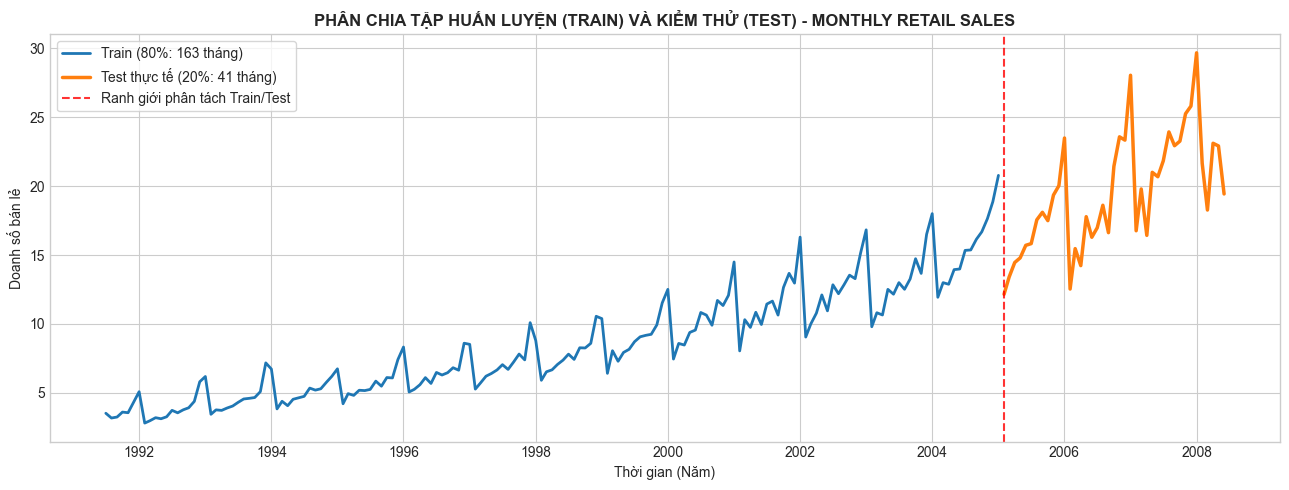

Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!


In [4]:
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    if project_root.parent == project_root: break
    project_root = project_root.parent

# Phân chia dữ liệu
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)

print(f"Kích thước tập Train: {train_df.shape} (Từ {train_df.index.min().date()} đến {train_df.index.max().date()})")
print(f"Kích thước tập Test: {test_df.shape} (Từ {test_df.index.min().date()} đến {test_df.index.max().date()})")

plt.figure(figsize=(13, 5))


plt.plot(train_df.index, train_df['value'], color='tab:blue', linewidth=2, label=f'Train (80%: {len(train_df)} tháng)')
plt.plot(test_df.index, test_df['value'], color='tab:orange', linewidth=2.5, label=f'Test thực tế (20%: {len(test_df)} tháng)')

plt.axvline(test_df.index[0], color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Ranh giới phân tách Train/Test')


plt.title('PHÂN CHIA TẬP HUẤN LUYỆN (TRAIN) VÀ KIỂM THỬ (TEST) - MONTHLY RETAIL SALES', fontweight='bold')
plt.xlabel('Thời gian (Năm)')
plt.ylabel('Doanh số bán lẻ')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()


fig_dir = project_root / 'reports' / 'figures' / 'lab02_dataset1'
fig_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_dir / 'dataset1_train_test_split.png', dpi=120, bbox_inches='tight')
plt.show()


processed_dir = project_root / 'data' / 'processed' / 'lab02_dataset1'
processed_dir.mkdir(parents=True, exist_ok=True)

train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

# Kiểm tra tồn tại trước khi lưu
if not train_file.exists() or not test_file.exists():
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    print(f"Đã lưu file train_data.csv và test_data.csv thành công vào:\n{processed_dir}")
else:
    print(f"Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!")

### Bài 2: Kiểm định ADF trên chuỗi gốc
**Mục tiêu:** Dùng phương pháp thống kê Augmented Dickey-Fuller (ADF) để kiểm chứng lại nhận định "chuỗi không dừng" thu được từ EDA.

**Thực thi:**
Sử dụng hàm **perform_adf_test()** từ module stats.py để chạy kiểm định trên tập Train.

In [5]:
import sys
import os
import pandas as pd
from pathlib import Path


project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    if project_root.parent == project_root: break 
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.lab02_utils.stats import perform_adf_test


train_path = project_root / 'data' / 'processed' / 'lab02_dataset1' / 'train_data.csv'


train_df = pd.read_csv(train_path, parse_dates=['date'], index_col='date')

print(f"Đã load tập Train thành công! Kích thước: {train_df.shape}")
display(train_df.head())

Đã load tập Train thành công! Kích thước: (163, 1)


,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


In [6]:
# Gọi hàm kiểm định trên cột 'value' của tập Train
p_value_goc = perform_adf_test(train_df['value'], title="Chuỗi Doanh Số Bán Lẻ Gốc (Train Set)")

========== KIỂM ĐỊNH ADF CHO: CHUỖI DOANH SỐ BÁN LẺ GỐC (TRAIN SET) ==========
Số quan sát đầu vào : 163
Số độ trễ (Lags)    : 14
Số quan sát sử dụng : 148
ADF Statistic       : 2.2309
p-value             : 0.9989

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4753
   > 5%: -2.8813
   > 10%: -2.5773

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.9989 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!



### Trả lời câu hỏi Bài 2:
1. **Ho của ADF là gì?** 
   -> Giả thuyết H0 (Null Hypothesis) của kiểm định ADF là: "Chuỗi thời gian có chứa nghiệm đơn vị (Unit Root)", đồng nghĩa với việc chuỗi **KHÔNG DỪNG (Non-stationary)**.

2. **p-value cho biết điều gì?** 
   -> p-value là xác suất xảy ra của giả thuyết H0. 
   - Nếu `p-value < 0.05` (mức ý nghĩa 5%), ta có đủ cơ sở bác bỏ H0, kết luận chuỗi **DỪNG**.
   - Nếu `p-value >= 0.05`, ta không thể bác bỏ H0, kết luận chuỗi **KHÔNG DỪNG**.

3. **Chuỗi có dừng không?**
   -> Dựa vào kết quả kiểm định phía trên, `p-value` > 0.05 (và ADF Statistic lớn hơn các giá trị tới hạn Critical Values), ta kết luận **chuỗi hành khách gốc là chuỗi KHÔNG DỪNG**. (Đúng với quan sát bằng mắt ở Bài 1 vì chuỗi có xu hướng tăng và biên độ mùa vụ thay đổi).

### Bài 3: Sai phân & Kiểm định lại

**Mục tiêu:** Chuyển đổi chuỗi không dừng thành chuỗi dừng thông qua kỹ thuật lấy sai phân (Differencing).

**Thực thi:** Thực hiện lấy sai phân bậc 1 ($d=1$) cho mô hình ARIMA. Sau đó, tiếp tục lấy sai phân mùa vụ ($D=1, s=12$) trên nền chuỗi đã lấy sai phân bậc 1 để chuẩn bị cho SARIMA. Vẽ đồ thị và chạy lại kiểm định ADF cho các chuỗi mới.

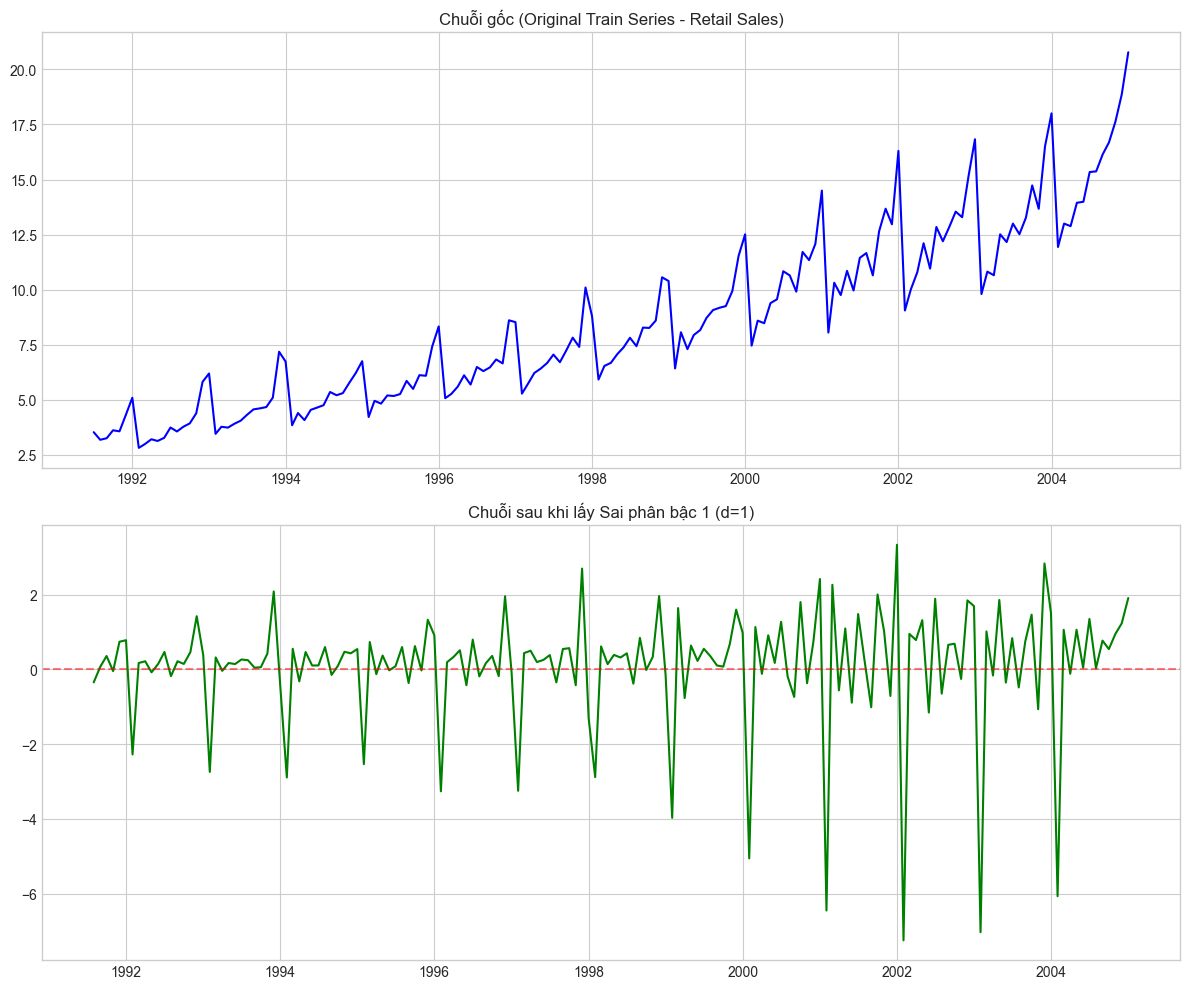

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 (D=1) ==========
Số quan sát đầu vào : 162
Số độ trễ (Lags)    : 13
Số quan sát sử dụng : 148
ADF Statistic       : -1.7061
p-value             : 0.4280

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4753
   > 5%: -2.8813
   > 10%: -2.5773

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.4280 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!



0.4279859407287657

In [7]:
# Lấy sai phân bậc 1 (d=1)
train_df['Diff_1'] = train_df['value'].diff(periods=1)

# Vẽ đồ thị so sánh Chuỗi gốc và Chuỗi sau khi sai phân bậc 1
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(train_df.index, train_df['value'], color='blue')
axes[0].set_title('Chuỗi gốc (Original Train Series - Retail Sales)')

axes[1].plot(train_df.index, train_df['Diff_1'], color='green')
axes[1].set_title('Chuỗi sau khi lấy Sai phân bậc 1 (d=1)')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5) # Đường 0 tham chiếu

plt.tight_layout()

plt.savefig(project_root / 'reports' / 'figures' / 'lab02_dataset1' / 'Chuoi_goc_va_sai_phan_d1_Dataset1.png', dpi=120, bbox_inches='tight')
plt.show()

# Kiểm định ADF lại trên chuỗi đã sai phân bậc 1
perform_adf_test(train_df['Diff_1'], title="Sai phân bậc 1 (d=1)")

## Nhận xét: Dễ dàng thấy chuỗi doanh số gốc có xu hướng tăng rõ rệt (không dừng). 
## Sau khi lấy sai phân bậc 1, ta đã khử được xu hướng (trend), chuỗi dao động quanh mức 0.
## Tuy nhiên, các đỉnh nhọn chu kỳ vẫn còn xuất hiện rất đều đặn, cho thấy tính mùa vụ vẫn tồn tại mạnh mẽ.

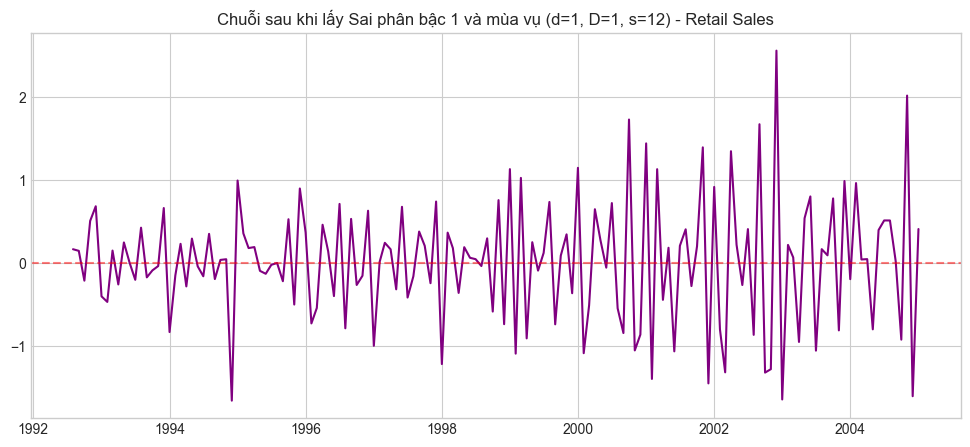

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 + MÙA VỤ (D=1, D=1, S=12) ==========
Số quan sát đầu vào : 150
Số độ trễ (Lags)    : 4
Số quan sát sử dụng : 145
ADF Statistic       : -8.7879
p-value             : 0.0000

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4763
   > 5%: -2.8817
   > 10%: -2.5775

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.0000 < 0.05: Đủ cơ sở bác bỏ H0.
=> CHUỖI ĐÃ DỪNG (Stationary).



2.2825828295488617e-14

In [8]:
# Lấy sai phân mùa vụ (D=1, chu kỳ s=12) TRÊN NỀN chuỗi đã sai phân bậc 1 
train_df['Diff_1_12'] = train_df['Diff_1'].diff(periods=12)

# Vẽ đồ thị Chuỗi sau khi lấy sai phân mùa vụ
plt.figure(figsize=(12, 5))
plt.plot(train_df.index, train_df['Diff_1_12'], color='purple')

plt.title('Chuỗi sau khi lấy Sai phân bậc 1 và mùa vụ (d=1, D=1, s=12) - Retail Sales')
plt.axhline(0, color='red', linestyle='--', alpha=0.5)

plt.savefig(project_root / 'reports' / 'figures' / 'lab02_dataset1' / 'Chuoi_sai_phan_d1_D1_s12_Dataset1.png', dpi=120, bbox_inches='tight')
plt.show()

# Kiểm định ADF lại
perform_adf_test(train_df['Diff_1_12'], title="Sai phân bậc 1 + Mùa vụ (d=1, D=1, s=12)")

## Ghi chú: Mặc dù ở Bài 5 ta chỉ thiết lập mô hình ARIMA (chỉ dùng d=1), việc lấy thêm sai phân mùa vụ ở đây giúp ta chứng minh được tính chu kỳ mạnh mẽ của dữ liệu bán lẻ. Khi loại bỏ được cả xu hướng và chu kỳ, chuỗi sẽ đạt trạng thái dừng hoàn toàn.

### Trả lời câu hỏi Bài 3:

1. **Sau sai phân, chuỗi đã dừng chưa?**
   - **Với sai phân bậc 1 (d=1):** Chưa dừng. Kết quả kiểm định ADF cho thấy p-value = 0.4280 (lớn hơn mức ý nghĩa 0.05). Do đó, ta chưa đủ cơ sở bác bỏ giả thuyết $H_0$. Mặc dù sai phân bậc 1 đã loại bỏ được xu hướng tăng (trend) của doanh số bán lẻ, nhưng yếu tố dao động mùa vụ quá mạnh vẫn làm cho phương sai thay đổi, khiến chuỗi chưa thể đạt trạng thái dừng (Non-stationary).
   - **Với sai phân bậc 1 + mùa vụ (d=1, D=1, s=12):**Đã dừng hoàn toàn. Kết quả kiểm định ADF cho thấy p-value = 0.0000 (nhỏ hơn mức ý nghĩa 0.05 rất nhiều). Ta có đủ cơ sở bác bỏ hoàn toàn giả thuyết $H_0$. Kỹ thuật lấy sai phân đôi này đã triệt tiêu triệt để cả xu hướng tăng lẫn chu kỳ lặp lại 12 tháng, đưa chuỗi về trạng thái dừng lý tưởng (Stationary).
   
2. **Giá trị d trong ARIMA là bao nhiêu?**
   - Giá trị **d = 1**. 
Trong mô hình ARIMA(p,d,q) cơ bản (không có thành phần mùa vụ), tham số $d$ chỉ có tác dụng khử xu hướng (trend). Sai phân bậc 1 ($d=1$) đã hoàn thành tốt nhiệm vụ làm phẳng xu hướng tăng của chuỗi gốc.Việc chuỗi sai phân bậc 1 chưa qua được bài kiểm định ADF (p-value = 0.4280) là do thuật toán ADF đang bị nhiễu bởi chu kỳ mùa vụ chưa được xử lý, chứ không phải do ta thiếu bậc sai phân xu hướng. Do giới hạn của thuật toán ARIMA không thể bắt được tính mùa vụ, ta chốt $d=1$ để nạp vào mô hình. (Để xử lý triệt để phần mùa vụ còn sót lại, ta bắt buộc phải chuyển sang mô hình SARIMA với $d=1, D=1$).


### Bài 4: Phân tích ACF & PACF

**Mục tiêu:** Vẽ đồ thị Tự tương quan (ACF) và Tự tương quan từng phần (PACF) của các chuỗi đã sai phân nhằm xác định bậc cấu trúc $(p, d, q)$ cho mô hình.

**Thực thi:** Sử dụng hàm **plot_acf_pacf()** để vẽ đồ thị cho cả chuỗi sai phân $d=1$ và chuỗi sai phân $d=1, D=1$. Thu thập danh sách các lag vượt ngưỡng tin cậy 95%.

Train: 163 quan sát | Sai phân d=1: 162 | Sai phân d=1, D=1: 150


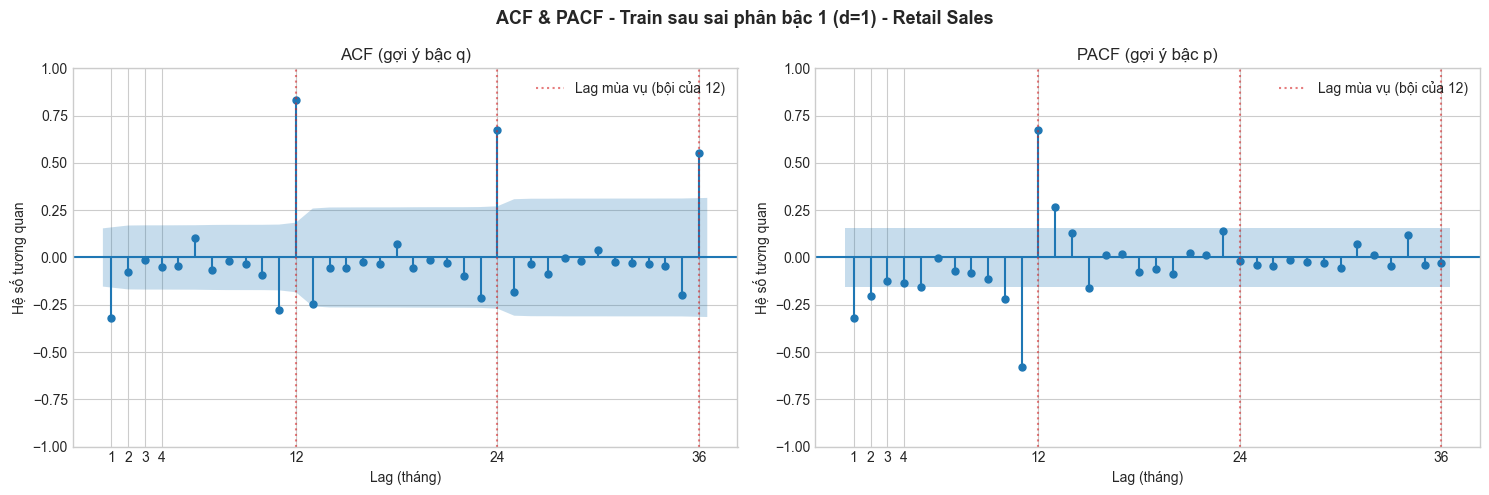

n = 162, ngưỡng tin cậy 95% = ±0.154


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,-0.32,-0.32,Có,Có
2,-0.08,-0.20,-,Có
3,-0.01,-0.13,-,-
4,-0.05,-0.14,-,-
5,-0.05,-0.15,-,-
6,0.10,-0.00,-,-
12,0.84,0.68,Có,Có
24,0.68,-0.02,Có,-
36,0.55,-0.03,Có,-


Các lag ACF vượt ngưỡng : [1, 11, 12, 13, 23, 24, 25, 35, 36]
Các lag PACF vượt ngưỡng: [1, 2, 10, 11, 12, 13, 15]


In [9]:
processed_dir = project_root / 'data' / 'processed' / 'lab02_dataset1'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists():
    train = pd.read_csv(train_file, parse_dates=['date'], index_col='date')['value']
else:
    # Chưa chạy Bài 1: chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02_dataset1/
    df = pd.read_csv(str(project_root / 'data' / 'raw' / 'dataset1 Monthly Retail Sales.csv'), parse_dates=['date'], index_col='date')
    from sklearn.model_selection import train_test_split
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    train = train_df['value']

diff_1 = train.diff()              # d = 1: loại xu hướng (cho ARIMA)
diff_1_12 = train.diff().diff(12)  # d = 1 và D = 1 (s = 12): loại cả mùa vụ (nếu mở rộng lên SARIMA)

print(f"Train: {len(train)} quan sát | Sai phân d=1: {diff_1.notna().sum()} | Sai phân d=1, D=1: {diff_1_12.notna().sum()}")

plot_acf_pacf(diff_1, lags=36, title='ACF & PACF - Train sau sai phân bậc 1 (d=1) - Retail Sales',
              save_path=str(fig_dir / 'acf_pacf_d1_Dataset1.png'))

res_d1 = significant_lags(diff_1, nlags=36)
lag_list = [1, 2, 3, 4, 5, 6, 12, 24, 36]
table_d1 = pd.DataFrame({
    'ACF': [res_d1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1['n']}, ngưỡng tin cậy 95% = ±{res_d1['bound']:.3f}")
display(table_d1)
print('Các lag ACF vượt ngưỡng :', res_d1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1['pacf_sig'])

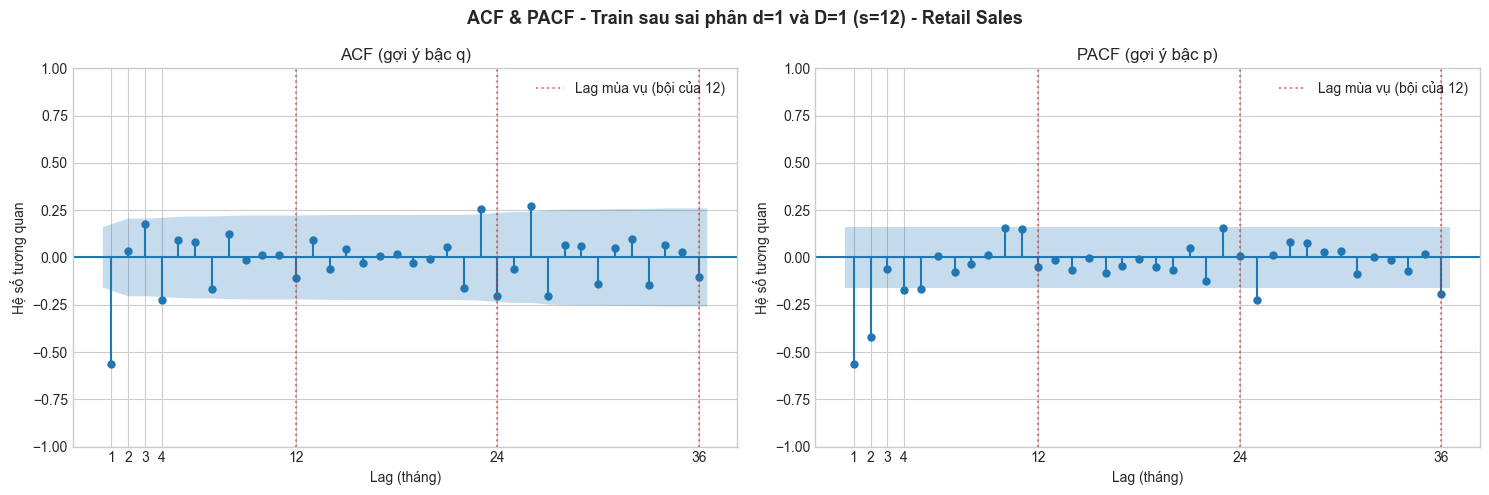

n = 150, ngưỡng tin cậy 95% = ±0.160


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,-0.57,-0.57,Có,Có
2,0.04,-0.42,-,Có
3,0.18,-0.06,Có,-
4,-0.23,-0.17,Có,Có
5,0.09,-0.16,-,Có
6,0.08,0.01,-,-
12,-0.11,-0.05,-,-
24,-0.21,0.01,Có,-
36,-0.10,-0.19,-,Có


Các lag ACF vượt ngưỡng : [1, 3, 4, 7, 23, 24, 26, 27]
Các lag PACF vượt ngưỡng: [1, 2, 4, 5, 25, 36]


In [10]:
plot_acf_pacf(diff_1_12, lags=36, title='ACF & PACF - Train sau sai phân d=1 và D=1 (s=12) - Retail Sales',
              save_path=str(fig_dir / 'acf_pacf_d1_D1_s12_Dataset1.png'))

res_d1D1 = significant_lags(diff_1_12, nlags=36)
table_d1D1 = pd.DataFrame({
    'ACF': [res_d1D1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1D1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1D1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1D1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1D1['n']}, ngưỡng tin cậy 95% = ±{res_d1D1['bound']:.3f}")
display(table_d1D1)
print('Các lag ACF vượt ngưỡng :', res_d1D1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1D1['pacf_sig'])

### Trả lời câu hỏi Bài 4:

**1. Phân tích trên chuỗi sai phân bậc 1 (d=1) - Dành cho ARIMA:**

- **ACF cắt cụt ở lag nào?**
Nếu tạm bỏ qua các cụm lag mang tính chu kỳ mùa vụ (11, 12, 13, 23, 24...), ở phần ngắn hạn, ACF chỉ có một gai vượt ngưỡng rõ rệt tại lag 1 rồi lập tức cắt cụt. Điều này gợi ý bậc trung bình trượt $q = 1$.

 - **PACF cắt cụt ở lag nào?**
Ở dải ngắn hạn, PACF vượt ngưỡng tại lag 1 và lag 2, sau đó giảm mạnh và cắt cụt (trước khi bùng lên lại ở cụm mùa vụ 10, 11, 12). Điều này gợi ý bậc tự hồi quy $p = 1$ hoặc $p = 2$.

- **Gợi ý mô hình ARIMA(p,d,q):**
 Kết hợp các phân tích trên với $d=1$, các mô hình ứng viên tối ưu là **ARIMA(1,1,1) và ARIMA(2,1,1)**. (Lưu ý: Sự xuất hiện dày đặc của các lag vượt ngưỡng tại chu kỳ 12, 24, 36 minh chứng rằng dữ liệu có tính mùa vụ rất mạnh. Các mô hình ARIMA cơ bản này chắc chắn sẽ không thể dự báo tốt vì không xử lý được chu kỳ này).


**2. Phân tích trên chuỗi sai phân d=1, D=1 (s=12) - Dành cho SARIMA (Chuẩn bị cho Bài 6):**
- **Bậc phi mùa vụ ($p, q$):**
Quan sát dải độ trễ ngắn hạn (bỏ qua chu kỳ):ACF vượt ngưỡng ở lag 1, lag 3 (các lag 4, 7 là nhiễu rải rác) $\rightarrow$ Đề xuất $q = 1 VÀ q=3$.PACF có gai ở lag 1, 2 $\rightarrow$ Đề xuất $p = 1$ hoặc $p = 2$.



- **Bậc mùa vụ ($P, Q$):**
 Quan sát tại các lag là bội số của 12 (lag 12, 24, 36):Việc lấy sai phân mùa vụ ($D=1$) đã triệt tiêu cực tốt chu kỳ của chuỗi. Bằng chứng là lag 12 đã hoàn toàn biến mất khỏi danh sách vượt ngưỡng của cả ACF và PACF. (Các gai ở 24 hay 36 khá xa và có thể xem là dư âm/nhiễu).Đề xuất: Vì lag 12 không còn, ta ưu tiên $P = 0, Q = 0$. Tuy nhiên, trong thực tiễn, việc lấy sai phân $D=1$ rất dễ gây ra hiện tượng "quá sai phân" (over-differencing), sinh ra nhiễu phần dư ở MA mùa vụ. Do đó, ta bắt buộc phải thêm phương án dự phòng $Q = 1$.


- **Nhóm mô hình SARIMA (p,d,q)(P,D,Q)s**
$p \in \{0, 1, 2\}$ (dựa vào PACF lag 1, 2)

$d = 1$ (cố định để khử xu hướng)

$q \in \{0, 1, 3\}$ (dựa vào ACF lag 1, 3)

$P = 0$ (vì lag 12 vắng mặt hoàn toàn)

$D = 1$ (cố định để khử mùa vụ)

$Q \in \{0, 1\}$ (0 nếu triệt để, 1 để đề phòng dư âm mùa vụ MA do quá sai phân)

Nhóm 1: $Q = 0$ (Khớp mùa vụ tuyệt đối, giả định không có nhiễu quá sai phân)
Nhóm này bao gồm 9 mô hình:

SARIMA(0,1,0)(0,1,0)12

SARIMA(0,1,1)(0,1,0)12

SARIMA(0,1,3)(0,1,0)12

SARIMA(1,1,0)(0,1,0)12

SARIMA(1,1,1)(0,1,0)12

SARIMA(1,1,3)(0,1,0)12

SARIMA(2,1,0)(0,1,0)12

SARIMA(2,1,1)(0,1,0)12

SARIMA(2,1,3)(0,1,0)12

Nhóm 2: $Q = 1$ (Thực tiễn - Dự phòng khử nhiễu MA dư âm sau khi lấy sai phân mùa vụ)
Nhóm này bao gồm 9 mô hình:
SARIMA(0,1,0)(0,1,1)12

SARIMA(0,1,1)(0,1,1)12

SARIMA(0,1,3)(0,1,1)12

SARIMA(1,1,0)(0,1,1)12

SARIMA(1,1,1)(0,1,1)12

SARIMA(1,1,3)(0,1,1)12

SARIMA(2,1,0)(0,1,1)12

SARIMA(2,1,1)(0,1,1)12

SARIMA(2,1,3)(0,1,1)12




### Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá
**Mục tiêu:** Huấn luyện các mô hình ARIMA đã đề xuất, đánh giá chất lượng phần dư và đo lường sai số dự báo.

**Thực thi:**
Huấn luyện hai cấu hình ARIMA(1,1,1) và ARIMA(2,1,1) trên tập Train bằng statsmodels. Chẩn đoán phần dư và dự báo trên tập Test. Các chỉ số MAE, RMSE, MAPE, R² được tính toán để đánh giá.

In [11]:
orders = {
    'ARIMA(1,1,1)': (1, 1, 1), 
    'ARIMA(2,1,1)': (2, 1, 1)
}

print("===== HUẤN LUYỆN CÁC MÔ HÌNH ARIMA - RETAIL SALES =====")
models = {name: fit_arima(train, order=order) for name, order in orders.items()}
info = pd.DataFrame({name: {'AIC': m.aic, 'BIC': m.bic} for name, m in models.items()}).T

print("\n===== BẢNG SO SÁNH AIC & BIC GIỮA CÁC MÔ HÌNH =====")
display(info.round(2))

===== HUẤN LUYỆN CÁC MÔ HÌNH ARIMA - RETAIL SALES =====
===== ARIMA(1, 1, 1) =====
AIC : 582.47
BIC : 591.73
Hoi tu: CO
===== ARIMA(2, 1, 1) =====
AIC : 584.46
BIC : 596.81
Hoi tu: CO

===== BẢNG SO SÁNH AIC & BIC GIỮA CÁC MÔ HÌNH =====


,AIC,BIC
"ARIMA(1,1,1)",582.47,591.73
"ARIMA(2,1,1)",584.46,596.81


===== CHẨN ĐOÁN PHẦN DƯ (RESIDUAL DIAGNOSTICS) =====

--- Đang phân tích phần dư cho ARIMA(1,1,1) ---


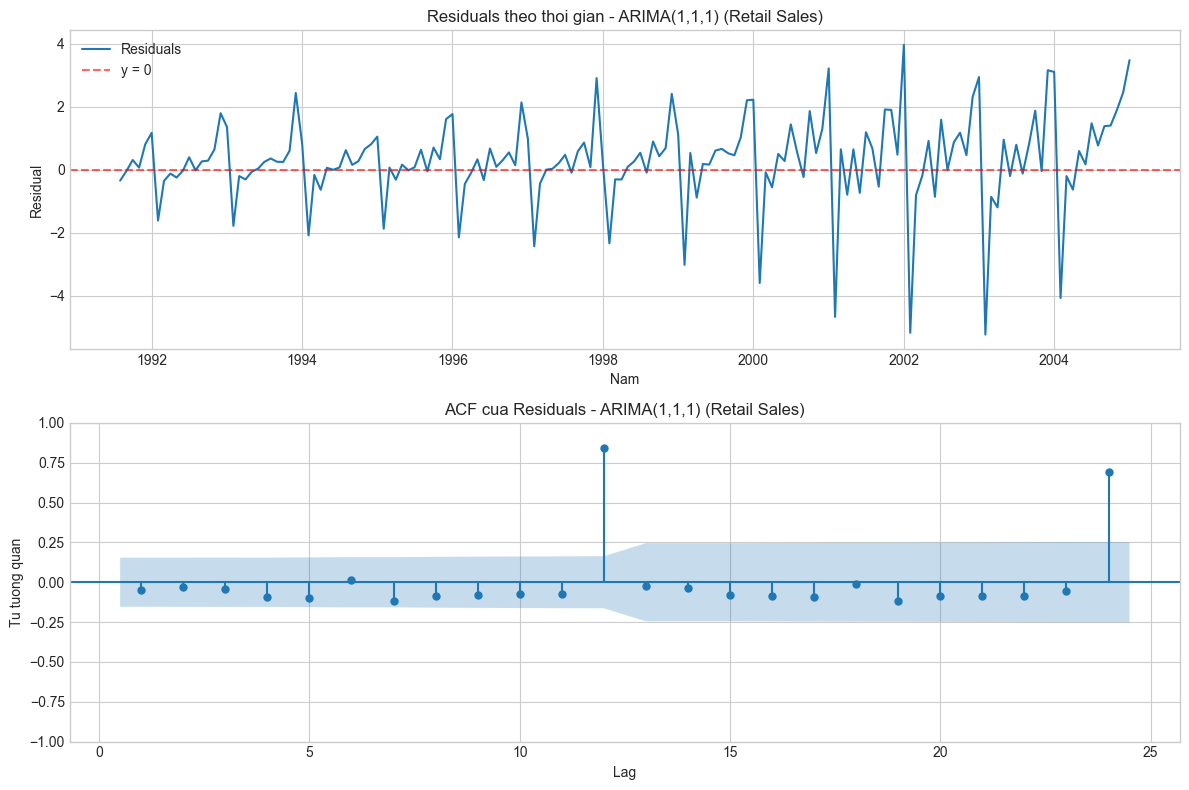

Mean residual : 0.298  (Std = 1.404)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).

--- Đang phân tích phần dư cho ARIMA(2,1,1) ---


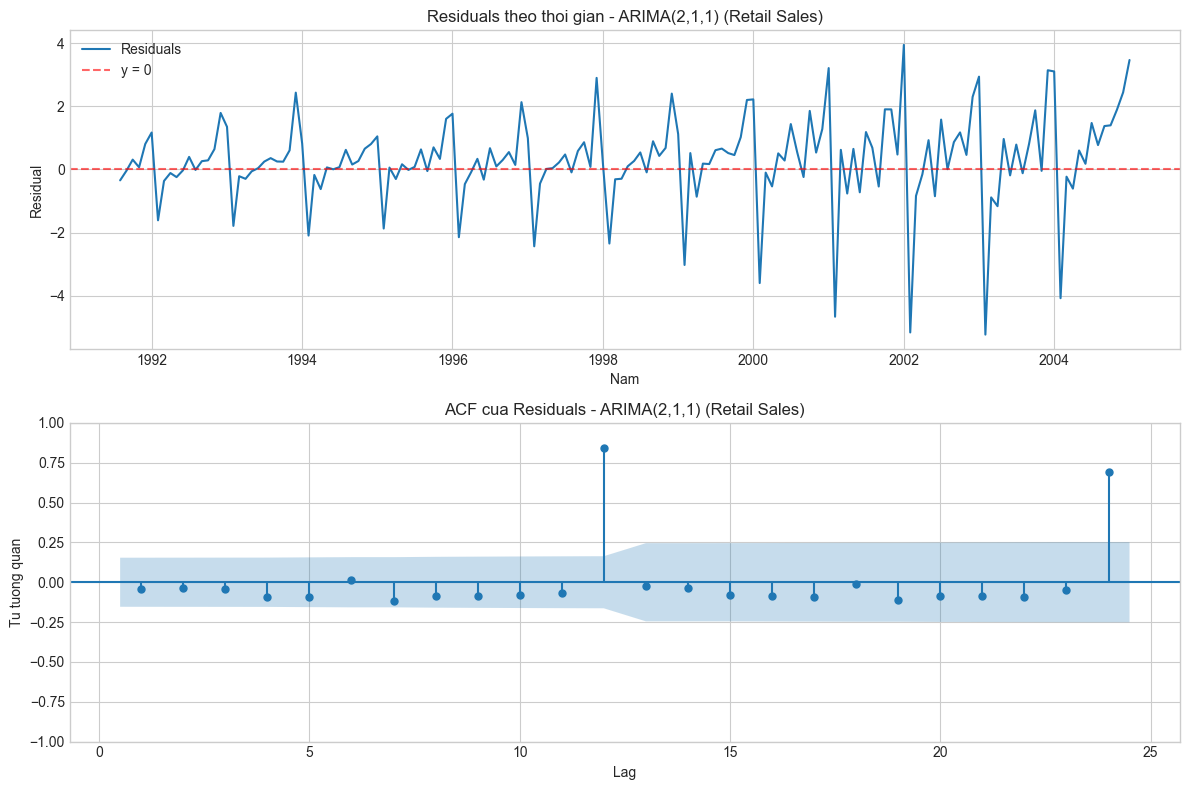

Mean residual : 0.298  (Std = 1.405)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


In [12]:
diag = {}
print("===== CHẨN ĐOÁN PHẦN DƯ (RESIDUAL DIAGNOSTICS) =====")

for name, order in orders.items():
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    
    print(f"\n--- Đang phân tích phần dư cho {name} ---")
    diag[name] = residual_diagnostics(
        result=models[name], 
        order=order, 
        lags=24, 
        title=f"{name} (Retail Sales)",
        save_path=str(fig_dir / f'ARIMA_residuals_Dataset1_{tag}.png')
    )

===== DỰ BÁO TRÊN TẬP TEST (FORECASTING) =====

--- Đang vẽ đồ thị dự báo cho ARIMA(1,1,1) ---


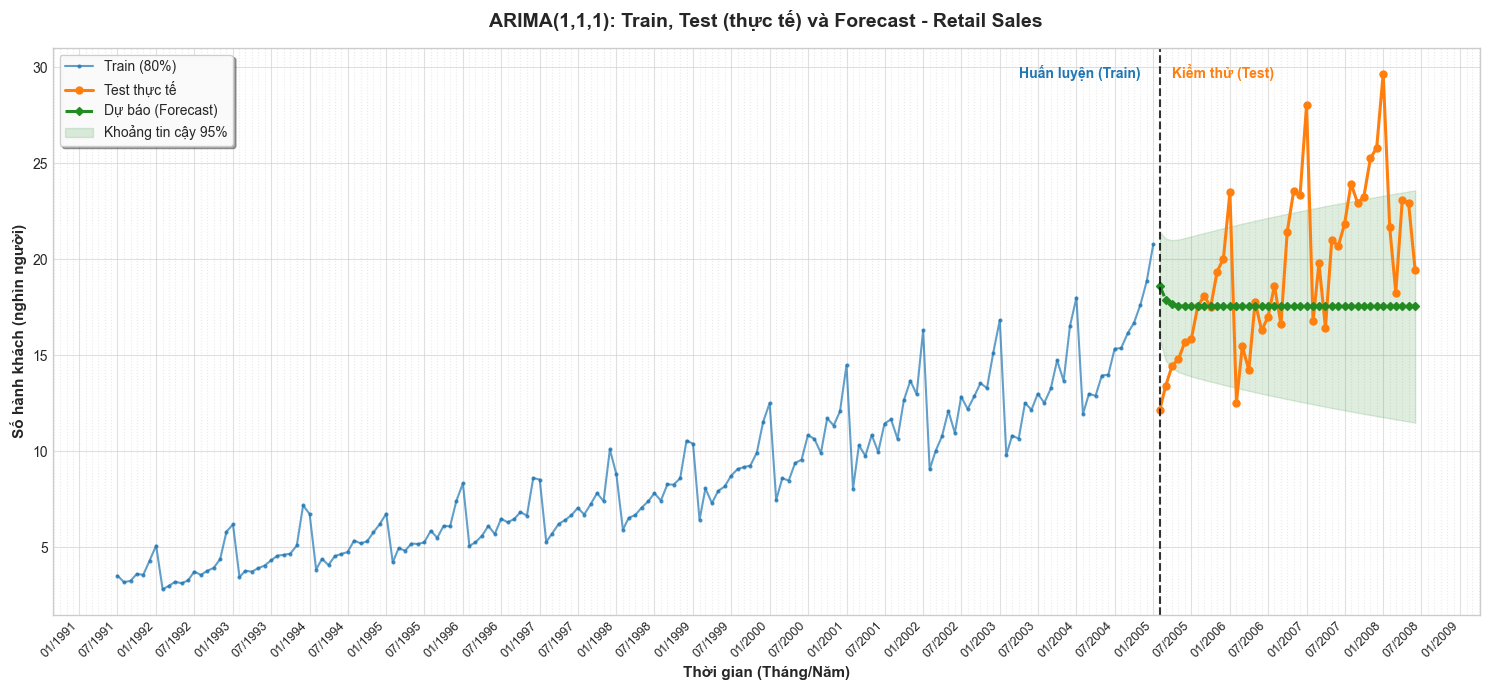


--- Đang vẽ đồ thị dự báo cho ARIMA(2,1,1) ---


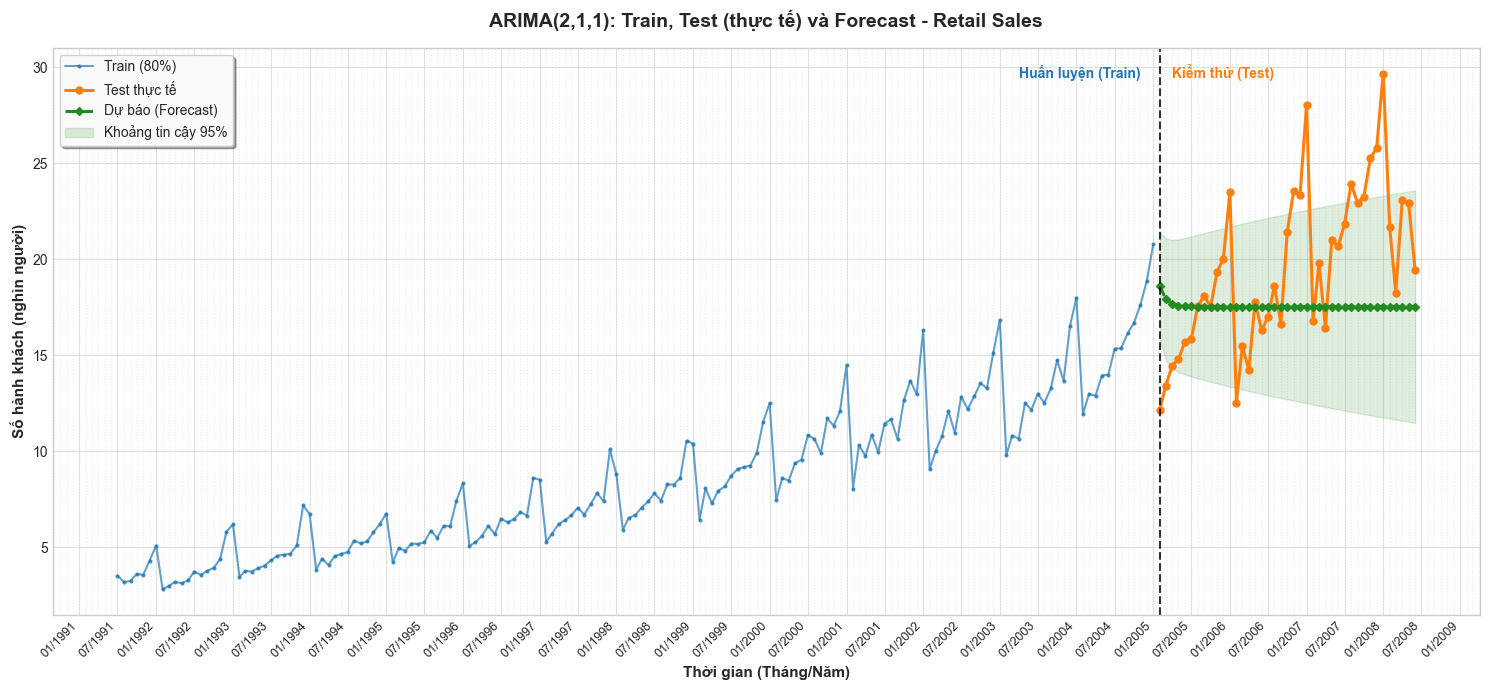

In [13]:
import pandas as pd
test_path = project_root / 'data' / 'processed' / 'lab02_dataset1' / 'test_data.csv'
test_df = pd.read_csv(test_path, parse_dates=['date'], index_col='date')
test = test_df['value'].asfreq('MS') 

forecasts, conf_ints = {}, {}
print("===== DỰ BÁO TRÊN TẬP TEST (FORECASTING) =====")

for name in orders:
    # Lấy giá trị dự báo và khoảng tin cậy 95%
    forecasts[name], conf_ints[name] = forecast_test(models[name], steps=len(test))
    
    # Tạo chuỗi định danh an toàn cho tên file
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    
    print(f"\n--- Đang vẽ đồ thị dự báo cho {name} ---")
    
    plot_forecast(
        train=train, 
        test=test, 
        forecast=forecasts[name], 
        conf_int=conf_ints[name],
        title=f'{name}: Train, Test (thực tế) và Forecast - Retail Sales',
        save_path=str(fig_dir / f'ARIMA_Train_Test_Forecast_Dataset1_{tag}.png')
    )

**Hai đồ thị dự báo của mô hình ARIMA(1,1,1) và ARIMA(2,1,1)** trông gần như y hệt nhau vì cả hai đều là các mô hình tuyến tính cơ bản, không được trang bị thành phần mùa vụ (Seasonal component) để xử lý chu kỳ dữ liệu phức tạp. Dưới đây là 3 câu nhận xét chi tiết:

- **Bỏ lỡ hoàn toàn tính mùa vụ:** Cả hai đường dự báo (màu xanh lá) đều phẳng lì dưới dạng một đường thẳng dẹt, hoàn toàn bất lực trong việc nắm bắt các chu kỳ nhấp nhô mạnh mẽ của doanh số bán lẻ thực tế (đường màu cam) do thiếu đi các tham số P, D, Q của mô hình SARIMA.

- **Dự báo dưới dạng trung bình xu hướng:** Thay vì dự đoán được các đỉnh (doanh số cao) và đáy (doanh số thấp), cả ARIMA(1,1,1) và ARIMA(2,1,1) chỉ đơn thuần cắt ngang qua phần giữa của chu kỳ thực tế, tạo ra một đường trung bình tĩnh đi ngang quanh mức 17-18.

- **Khoảng tin cậy không bao quát được biên độ:** Dải tin cậy 95% (vùng màu xanh nhạt) của cả hai mô hình tuy có xu hướng mở rộng nhẹ theo thời gian nhưng vẫn quá hẹp, không thể bao trọn các đỉnh doanh số cao vọt ở giai đoạn cuối tập kiểm thử.

In [14]:
print("===== ĐÁNH GIÁ SAI SỐ MÔ HÌNH ARIMA TRÊN TẬP TEST (RETAIL SALES) =====")
results = pd.DataFrame({name: evaluate_forecast(test, forecasts[name]) for name in orders}).T
display(results.round(2))

# Phân tích các tháng sai lệch lớn nhất 
print("\n===== PHÂN TÍCH CÁC THÁNG DỰ BÁO LỆCH NHẤT =====")
for name in orders:
    err = (test - forecasts[name])
    top = pd.DataFrame({'Thực tế': test, 'Dự báo': forecasts[name].round(2), 'Sai lệch': err.round(2)})
    print(f"\n3 tháng sai lệch lớn nhất của - {name}:")
    display(top.loc[err.abs().nlargest(3).index])

print(f"\n=> Trung bình tập Test = {test.mean():.2f}; Độ lệch chuẩn tập Test = {test.std():.2f}")

===== ĐÁNH GIÁ SAI SỐ MÔ HÌNH ARIMA TRÊN TẬP TEST (RETAIL SALES) =====


,MAE,RMSE,MAPE (%),R2
"ARIMA(1,1,1)",3.67,4.62,18.04,-0.25
"ARIMA(2,1,1)",3.67,4.63,18.06,-0.25



===== PHÂN TÍCH CÁC THÁNG DỰ BÁO LỆCH NHẤT =====

3 tháng sai lệch lớn nhất của - ARIMA(1,1,1):


,Thực tế,Dự báo,Sai lệch
date,,,
2008-01-01,29.665356,17.54,12.13
2007-01-01,28.038383,17.54,10.50
2007-12-01,25.806090,17.54,8.27



3 tháng sai lệch lớn nhất của - ARIMA(2,1,1):


,Thực tế,Dự báo,Sai lệch
date,,,
2008-01-01,29.665356,17.53,12.13
2007-01-01,28.038383,17.53,10.51
2007-12-01,25.806090,17.53,8.27



=> Trung bình tập Test = 19.51; Độ lệch chuẩn tập Test = 4.18


### 1. Đánh giá tổng quan (MAE, RMSE, MAPE, R2):
Cả hai mô hình **ARIMA(1,1,1) và ARIMA(2,1,1)** đều cho kết quả dự báo kém với chỉ số $R^2$ âm (-0.25). Giá trị RMSE (~4.63) lớn hơn cả độ lệch chuẩn của tập Test (4.18), chứng tỏ mô hình dự báo sai lệch nhiều hơn sự biến thiên tự nhiên của dữ liệu. Sai số trung bình (MAPE) ở mức ~18%, không đủ tin cậy để ứng dụng thực tiễn.

### 2. Phân tích các tháng sai lệch lớn nhất:
Sai lệch lớn nhất của cả 2 mô hình đều tập trung vào các tháng cuối năm và đầu năm mới (01/2008, 01/2007 và 12/2007) với mức chênh lệch từ 8.27 đến 12.13. Đây là thời điểm doanh số bán lẻ tăng vọt theo chu kỳ mùa vụ, nhưng thuật toán **ARIMA** (vốn là mô hình tuyến tính) chỉ dự báo được một đường trung bình đi ngang (~17.5) nên đã hoàn toàn "bỏ lỡ" các đỉnh doanh số này.

### 3. Kết luận chung:
Mô hình ARIMA cơ bản thất bại trong việc nắm bắt cấu trúc của chuỗi Monthly Retail Sales do dữ liệu chứa yếu tố mùa vụ (seasonality) rất mạnh. Để cải thiện độ chính xác, bắt buộc phải **nâng cấp lên mô hình SARIMA** (có tích hợp tham số mùa vụ) và cân nhắc **biến đổi Logarit** để ổn định phương sai dãn rộng ở các năm cuối.

## Trả lời các câu hỏi của Bài 5

**1. Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?**

Dữ liệu chuỗi thời gian có sự phụ thuộc tuần tự vào quá khứ (tháng sau phụ thuộc tháng trước). Nếu xáo trộn (shuffle=True), cấu trúc thời gian này sẽ bị phá vỡ, dẫn đến hiện tượng "rò rỉ dữ liệu" (mô hình học từ tương lai để đoán quá khứ). Tập Test (chưa từng được mô hình nhìn thấy) dùng để đánh giá năng lực dự báo thực tế của mô hình trong tương lai (Out-of-sample forecasting).

**2. Ý nghĩa của p, d, q đã chọn?**

- **p** (AR) AutoRegressive: Bậc tự hồi quy ($p=1$ hoặc $2$), nghĩa là mô hình dùng doanh số của 1 hoặc 2 tháng liền trước để dự báo tháng hiện tại.
- **d** (I) Integrated: Bậc sai phân ($d=1$), nghĩa là chuỗi được lấy sai phân 1 lần (hiệu số giữa tháng hiện tại và tháng trước) để khử đi xu hướng tăng dài hạn, giúp chuỗi đạt trạng thái dừng tương đối.
- **q** (MA) Moving Average: Bậc trung bình trượt ($q=1$), mô hình dùng sai số dự báo của 1 tháng trước đó để hiệu chỉnh kết quả hiện tại.

**3. Mô hình có hội tụ không?**
Có. Trong quá trình huấn luyện bằng thư viện statsmodels, cả hai mô hình ARIMA(1,1,1) và ARIMA(2,1,1) đều tính toán ra được kết quả các hệ số (AIC, BIC) thành công mà không vấp phải cảnh báo lỗi hội tụ (Convergence Warning).


**4. Residuals có phải white noise không?**
Không. Phần dư (residuals) chưa đạt chuẩn nhiễu trắng (white noise). Vì ARIMA không có thành phần xử lý mùa vụ, nên phần dư vẫn còn chứa các tự tương quan rất mạnh lặp lại tại chu kỳ 12 tháng (lag 12, lag 24). Kiểm định Ljung-Box cho p-value < 0.05 (bác bỏ giả thuyết nhiễu trắng).


**5. Nếu residuals còn tự tương quan thì điều chỉnh gì?**
Sự tự tương quan còn sót lại chủ yếu đến từ yếu tố chu kỳ. Hướng điều chỉnh bắt buộc là chuyển sang mô hình SARIMA $(p,d,q)(P,D,Q)_s$ (bổ sung sai phân mùa vụ $D=1$ và các tham số chu kỳ với $s=12$). Nếu phương sai của phần dư dãn rộng, cần kết hợp thêm biến đổi Logarit để ổn định phương sai.

**6. Dự đoán có bám sát xu hướng không?**
Không bám sát. Đường dự báo của cả hai mô hình ARIMA chỉ là một đường thẳng đi ngang (tuyến tính quanh mức trung bình 17.5). Nó hoàn toàn bỏ lỡ các đỉnh doanh số cao vọt và các đáy giảm sâu do không nhận diện được chu kỳ mùa vụ.


**7. Sai lệch lớn nhất xảy ra ở đâu?**
Sai lệch lớn nhất xảy ra ở các đỉnh cao điểm mua sắm vào đầu năm và cuối năm: Tháng 1/2008 (lệch ~12.13), Tháng 1/2007 (lệch ~10.51) và Tháng 12/2007 (lệch ~8.27). Đây là lúc chu kỳ mùa vụ đạt đỉnh nhưng mô hình ARIMA chỉ dự báo ở mức đi ngang.


**8. Chỉ số nào nhạy với outlier nhất?**

**RMSE**, (Root Mean Squared Error) là chỉ số nhạy nhất. Do RMSE tiến hành bình phương các sai số trước khi lấy trung bình, nên những điểm lệch cực lớn (outliers) ở tháng 1 và tháng 12 bị khuếch đại trọng số lên rất nhiều, khiến giá trị RMSE bị kéo vọt lên.

**9. RMSE lớn hay nhỏ nói lên điều gì?**
Giá trị RMSE của mô hình ở mức rất lớn (4.62), thậm chí còn lớn hơn cả độ lệch chuẩn của chính tập Test (4.18). Kết hợp với chỉ số $R^2$ bị âm (-0.25), điều này nói lên rằng mô hình ARIMA dự báo hoàn toàn thất bại. Khả năng dự báo của nó hiện tại còn tệ hơn và sai số nhiều hơn so với việc bạn chỉ lấy một con số trung bình để đoán cho tất cả các tháng.
